In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.optimizers import Adam

In [8]:
# Set image dimensions expected by VGG16
size = (224, 224)
data_dir = r'fashion mnist/' 

# Load training split
train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    image_size=size,
    validation_split=0.2,
    batch_size=16,
    subset='training',
    seed=42
)

# Load validation split
test_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    image_size=size,
    validation_split=0.2,
    batch_size=16,
    subset='validation',
    seed=42
)

class_names = train_ds.class_names
print("Classes identified:", class_names)

Found 12832 files belonging to 11 classes.
Using 10266 files for training.
Found 12832 files belonging to 11 classes.
Using 2566 files for validation.
Classes identified: ['Ankle-boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt-top', 'Trouser', 'train']


In [9]:
# Load VGG16 with pre-trained ImageNet weights (downloaded automatically by Keras)
base = VGG16(
    weights='imagenet',
    input_shape=(224, 224, 3),
    include_top=False
)

# Freeze base VGG16 layers
base.trainable = False

# Construct custom classification network
model = models.Sequential([
    layers.Lambda(preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ ?                           │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train frozen base model (using subsets for quick laboratory execution)
history = model.fit(
    train_ds.take(100),
    validation_data=test_ds.take(10),
    epochs=3
)

Epoch 1/3


C:\Users\Lenovo\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(



100/100 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step - accuracy: 0.3094 - loss: 3.4830 - val_accuracy: 0.7063 - val_loss: 1.0533
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 161s 2s/step - accuracy: 0.5669 - loss: 1.5645 - val_accuracy: 0.7563 - val_loss: 0.9060
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 161s 2s/step - accuracy: 0.6756 - loss: 1.1374 - val_accuracy: 0.7688 - val_loss: 0.8303


In [11]:
# Evaluate model loss and accuracy
loss, accuracy = model.evaluate(test_ds.take(10))

print("Loss:", loss)
print(f"Accuracy: {accuracy * 100:.2f}%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 15s 2s/step - accuracy: 0.7750 - loss: 0.7522
Loss: 0.7522428631782532
Accuracy: 77.50%


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step


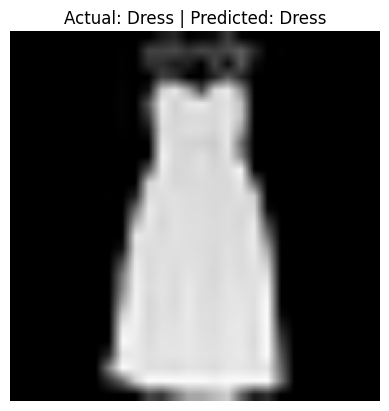

In [12]:
# Predict and display a sample image
for images, labels in test_ds.take(1):
    preds = model.predict(images[:1])
    pred_index = np.argmax(preds[0])
    
    actual_label = class_names[labels[0]]
    predicted_label = class_names[pred_index]
    
    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title(f"Actual: {actual_label} | Predicted: {predicted_label}")
    plt.axis("off")
    plt.show()
    break

In [13]:
# Unfreeze base model for fine-tuning
base.trainable = True

# Freeze all layers except top convolutional block (block5)
for layer in base.layers[:-6]:
    layer.trainable = False

# Recompile with a lower learning rate
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Fine-tuning top layers of VGG16...")
fine_tune_history = model.fit(
    train_ds.take(100),
    validation_data=test_ds.take(10),
    epochs=2
)

# Evaluate fine-tuned model
ft_loss, ft_accuracy = model.evaluate(test_ds.take(10))
print("Fine-Tuned Loss:", ft_loss)
print(f"Fine-Tuned Accuracy: {ft_accuracy * 100:.2f}%")

Fine-tuning top layers of VGG16...
Epoch 1/2
100/100 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.7556 - loss: 0.7829 - val_accuracy: 0.7812 - val_loss: 0.6248
Epoch 2/2
100/100 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - accuracy: 0.8313 - loss: 0.4601 - val_accuracy: 0.7812 - val_loss: 0.6081
10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.7812 - loss: 0.6090
Fine-Tuned Loss: 0.6090126633644104
Fine-Tuned Accuracy: 78.12%
